# Notebook 04: comparison
Our RH-STA* vs the original greedy vs our Task 2 GA, on the same worlds.

Metrics:
- **Success rate** - % of episodes where all coins are collected. We also count how many levels each agent won in every seed.
- **Completion time** - seconds to collect all coins (only won episodes).
- **RACR (our metric)** - coins per second x remaining life. Fast but losing a lot of life gets a lower score, and it still gives credit for coins collected in lost episodes.
- **HEI (our metric)** - % of time the character is very close to a hazard (within 0.05) without being hit. Shows how risky the agent plays even when it survives.
- Also remaining life, path length and planning time per move (measured with episodes running in parallel, so higher than in the real game - see notebook 02).

In [1]:
# mount google drive and make the folders we save everything into
import os, sys, json, subprocess, datetime, importlib
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/COMP6009_Assignment-Part A'   # all our files go here
PATHS = {
    'code':         f'{ROOT}/code',                          # the cointex_parta package
    'data':         f'{ROOT}/data',                          # cointex.kv, level table
    'config':       f'{ROOT}/config',                        # experiment_config.json
    'greedy':       f'{ROOT}/results/01_greedy_baseline',
    'proposed':     f'{ROOT}/results/02_proposed',
    'ga':           f'{ROOT}/results/03_ga_task2',
    'compare':      f'{ROOT}/results/04_comparison',
    'report_figs':  f'{ROOT}/report_assets/figures',         # final figures for the report/slides
    'report_tabs':  f'{ROOT}/report_assets/tables',          # final tables for the report
    'deliverables': f'{ROOT}/deliverables',
    'logs':         f'{ROOT}/logs',
}
for p in PATHS.values():
    os.makedirs(p, exist_ok=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pygad==3.3.1'], check=True)
if PATHS['code'] not in sys.path:
    sys.path.insert(0, PATHS['code'])

def log_run(notebook, **info):
    # keep a log of every run
    info.update(notebook=notebook, at=datetime.datetime.now().isoformat(timespec='seconds'))
    with open(f"{PATHS['logs']}/run_log.jsonl", 'a') as f:
        f.write(json.dumps(info) + '\n')

print('Project root:', ROOT)

Mounted at /content/drive
Project root: /content/drive/MyDrive/COMP6009_Assignment-Part A


In [2]:
# load our code (written to drive by notebook 00) and the experiment settings
assert os.path.exists(f"{PATHS['code']}/cointex_parta/__init__.py"), \
    'code not found on Drive (notebook 00 writes it)'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import cointex_parta
from cointex_parta import runner, plots, sim, levels
plots.style()
CFG = json.load(open(f"{PATHS['config']}/experiment_config.json"))
LEVELS, SEEDS = CFG['levels'], list(range(CFG['n_seeds']))
WORKERS = os.cpu_count()
print(f"cointex_parta v{cointex_parta.__version__} | {len(LEVELS)} levels x {len(SEEDS)} seeds | {WORKERS} CPU workers")
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

for sub in ('figures', 'tables'): os.makedirs(f"{PATHS['compare']}/{sub}", exist_ok=True)
from scipy import stats
OUT = PATHS['compare']
for sub in ('stats', 'stress'): os.makedirs(f'{OUT}/{sub}', exist_ok=True)
AGENTS = ['greedy', 'ga_task2', 'proposed']

cointex_parta v1.0.0 | 24 levels x 50 seeds | 12 CPU workers


## 1. Load the results

In [3]:
srcs = {'greedy': f"{PATHS['greedy']}/per_run.csv", 'ga_task2': f"{PATHS['ga']}/per_run.csv",
        'proposed': f"{PATHS['proposed']}/main_per_run.csv"}
missing = [a for a, p in srcs.items() if not os.path.exists(p)]
assert not missing, f'missing results for {missing}'
df = pd.concat([pd.read_csv(p) for p in srcs.values()], ignore_index=True)
df = df[df.hazard_speed == 1.0]
counts = df.groupby('agent').size(); print(counts.to_string())
assert counts.nunique() == 1, 'agents have different numbers of episodes'

agent
ga_task2    1200
greedy      1200
proposed    1200


## 2. Overall results

,Original greedy,GA (Task 2),Proposed (RH-STA*)
episodes,1200.00,1200.00,1200.00
success_rate,80.17,100.00,100.00
levels_always_won,4.00,24.00,24.00
levels_majority_won,20.00,24.00,24.00
death_rate,19.83,0.00,0.00
timeout_rate,0.00,0.00,0.00
completion_time_mean,5.23,6.99,4.30
completion_time_median,5.02,6.22,4.22
remaining_life_mean,58.51,93.28,99.52
racr_mean,1.49,2.06,3.18


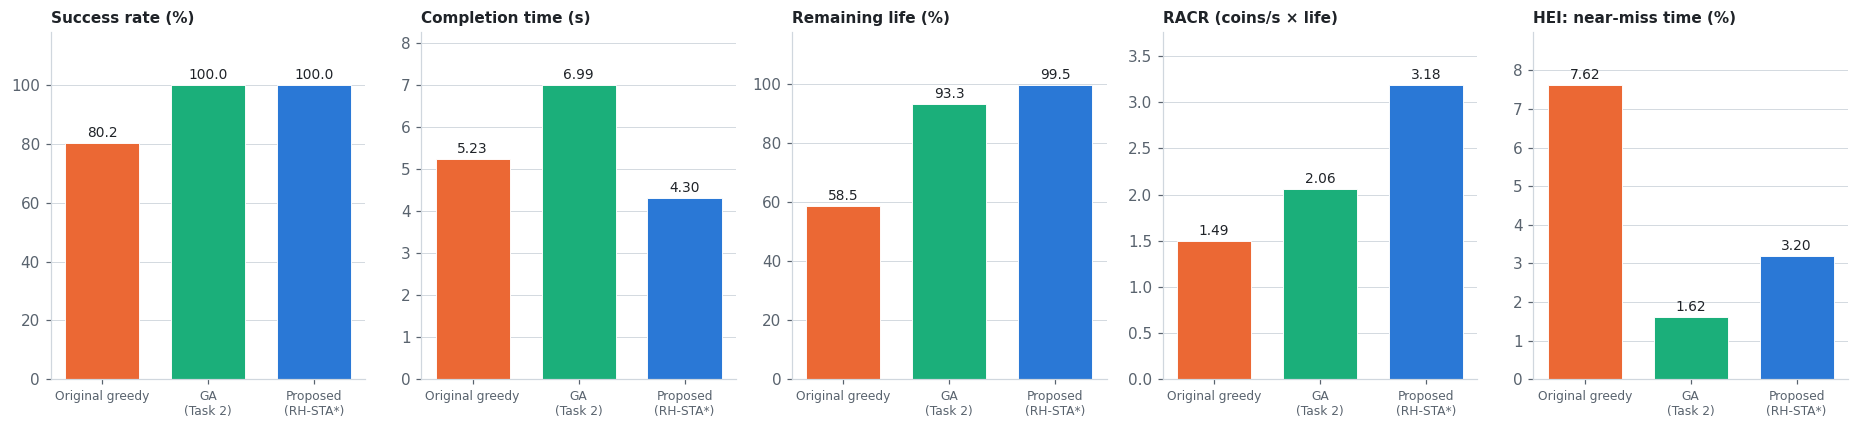

In [4]:
s = runner.summarise(df).set_index('agent').loc[AGENTS]
s['levels_always_won'] = df.groupby(['agent', 'level']).won.mean().eq(1).groupby('agent').sum()
s['levels_majority_won'] = df.groupby(['agent', 'level']).won.mean().ge(0.5).groupby('agent').sum()
table1 = s[['episodes', 'success_rate', 'levels_always_won', 'levels_majority_won', 'death_rate', 'timeout_rate',
            'completion_time_mean', 'completion_time_median', 'remaining_life_mean', 'racr_mean',
            'near_miss_pct_mean', 'path_length_mean', 'plan_ms_mean']].round(2)
table1.index = [plots.label(a) for a in table1.index]
table1.to_csv(f"{OUT}/tables/table1_overall.csv")
table1.to_csv(f"{PATHS['report_tabs']}/table1_overall.csv")
open(f"{PATHS['report_tabs']}/table1_overall.md", 'w').write(table1.T.to_markdown())
display(table1.T)
summary = runner.summarise(df)
fig = plots.overall_bars(summary, ['success_rate', 'completion_time_mean', 'remaining_life_mean', 'racr_mean', 'near_miss_pct_mean'], AGENTS,
                         ['Success rate (%)', 'Completion time (s)', 'Remaining life (%)', 'RACR (coins/s × life)', 'HEI: near-miss time (%)'],
                         fmts=['%.1f', '%.2f', '%.1f', '%.2f', '%.2f'], figsize=(17, 4))
for d in (f'{OUT}/figures', PATHS['report_figs']): plots.save(fig, d, 'fig_overall_kpis.png')
plt.show()

## 3. Results per level

,success_rate|greedy,success_rate|ga_task2,success_rate|proposed,completion_time_mean|greedy,completion_time_mean|ga_task2,completion_time_mean|proposed,remaining_life_mean|greedy,remaining_life_mean|ga_task2,remaining_life_mean|proposed,racr_mean|greedy,racr_mean|ga_task2,racr_mean|proposed
level,,,,,,,,,,,,
1,100.0,100.0,100.0,2.09,3.42,1.94,96.90,99.60,100.00,2.49,1.78,2.65
2,100.0,100.0,100.0,3.31,3.95,2.77,95.20,99.33,100.00,2.39,2.24,2.93
3,98.0,100.0,100.0,4.57,4.90,3.74,84.67,97.67,99.20,2.23,2.47,3.22
4,94.0,100.0,100.0,4.11,4.78,3.32,88.90,97.80,100.00,2.21,2.27,3.05
5,90.0,100.0,100.0,5.80,5.97,4.42,69.30,94.80,98.20,1.80,2.56,3.37
6,92.0,100.0,100.0,4.63,5.49,3.72,73.10,96.10,99.90,1.91,2.27,3.26
7,72.0,100.0,100.0,4.08,6.64,3.53,49.84,92.00,99.44,1.23,1.57,2.88
8,92.0,100.0,100.0,5.80,6.19,4.57,60.32,95.28,99.20,1.56,2.51,3.29
9,90.0,100.0,100.0,4.70,5.82,3.84,64.00,94.72,100.00,1.65,2.14,3.16


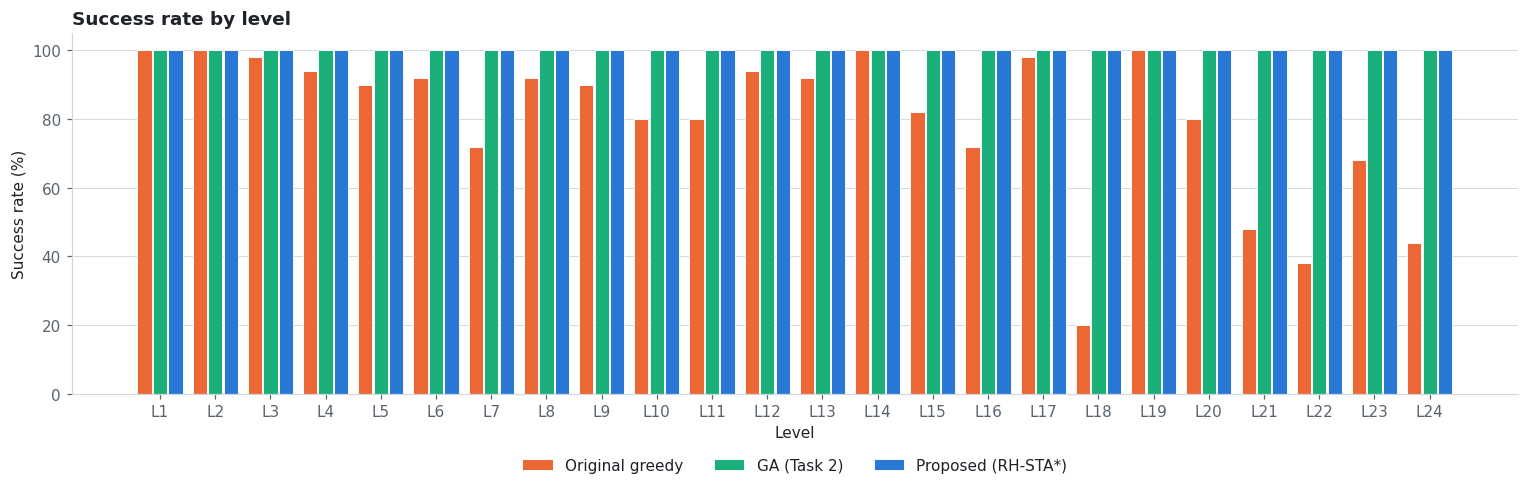

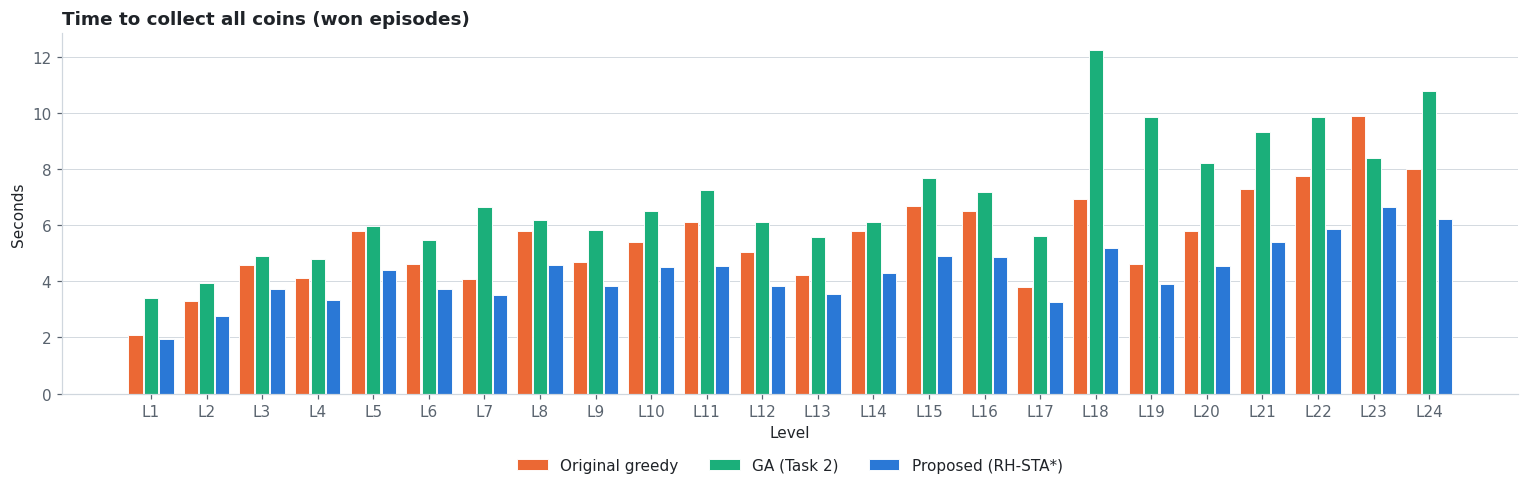

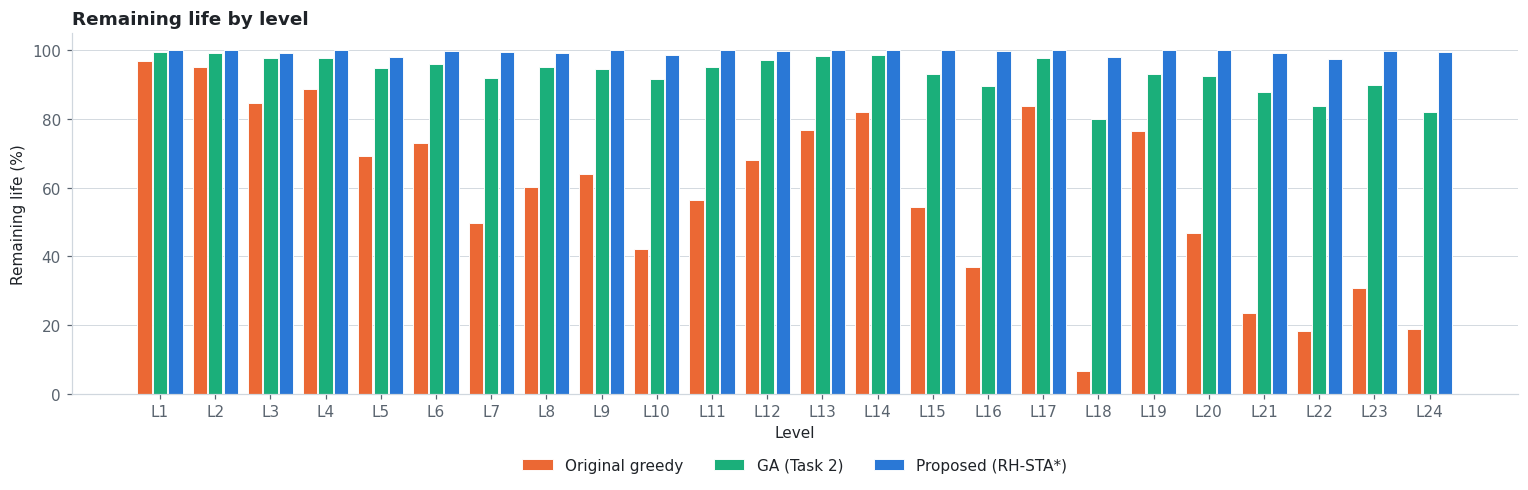

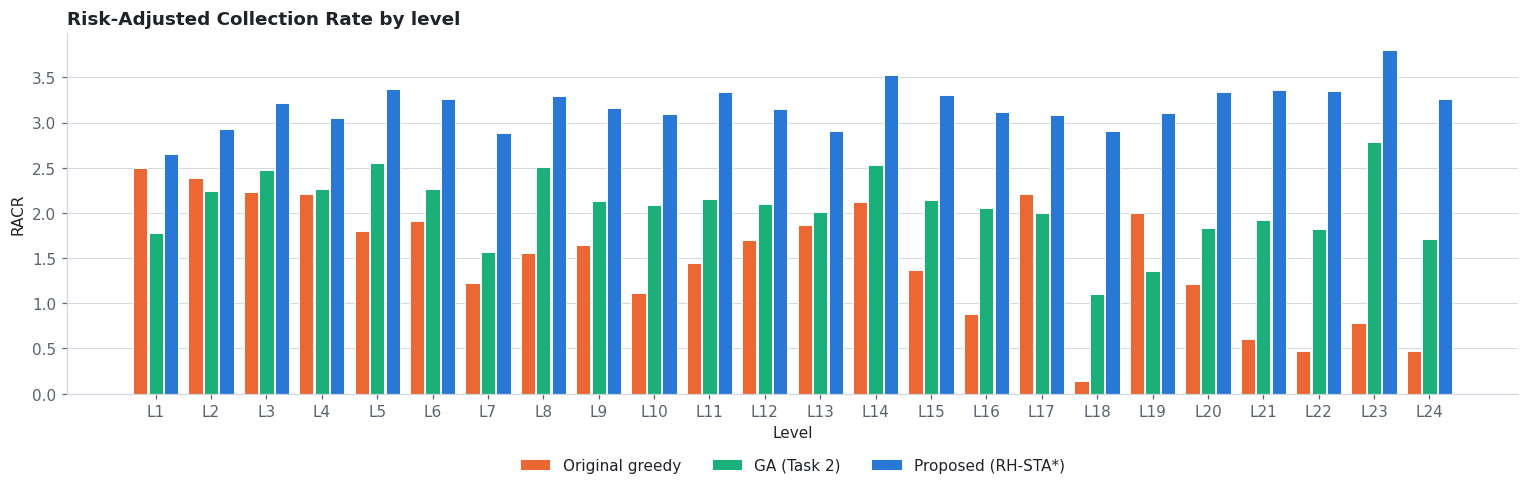

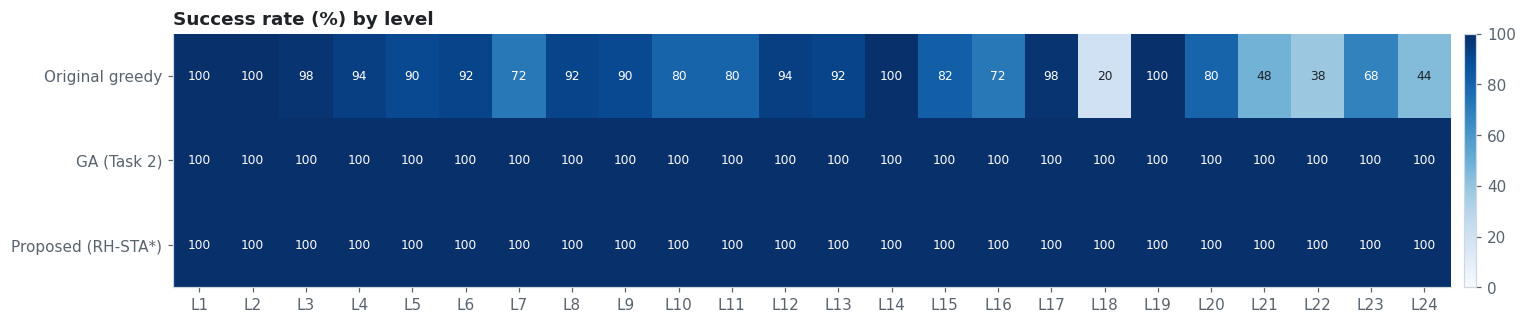

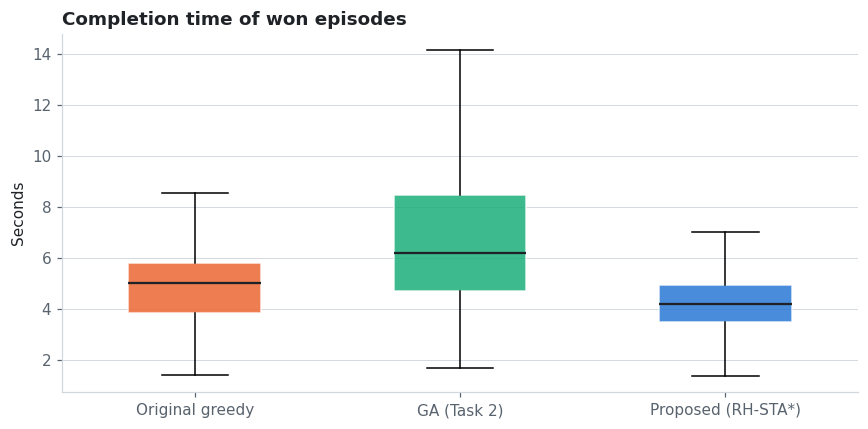

In [5]:
pl = runner.summarise(df, by=('agent', 'level'))
wide = pl.pivot(index='level', columns='agent', values=['success_rate', 'completion_time_mean', 'remaining_life_mean', 'racr_mean'])[
    [(m, a) for m in ['success_rate', 'completion_time_mean', 'remaining_life_mean', 'racr_mean'] for a in AGENTS]].round(2)
wide.columns = [f'{m}|{a}' for m, a in wide.columns]
wide.to_csv(f"{OUT}/tables/table2_per_level.csv"); wide.to_csv(f"{PATHS['report_tabs']}/table2_per_level.csv")
display(wide)
figs = [
    (plots.per_level_bars(df, 'won', AGENTS, 'Success rate (%)', 'Success rate by level', scale=100, ylim=(0, 105)), 'fig_success_by_level.png'),
    (plots.per_level_bars(df, 'completion_time', AGENTS, 'Seconds', 'Time to collect all coins (won episodes)'), 'fig_time_by_level.png'),
    (plots.per_level_bars(df, 'remaining_life', AGENTS, 'Remaining life (%)', 'Remaining life by level', ylim=(0, 105)), 'fig_life_by_level.png'),
    (plots.per_level_bars(df, 'racr', AGENTS, 'RACR', 'Risk-Adjusted Collection Rate by level'), 'fig_racr_by_level.png'),
    (plots.success_heatmap(df, AGENTS), 'fig_success_heatmap.png'),
    (plots.completion_box(df, AGENTS), 'fig_completion_box.png'),
]
for fig, name in figs:
    for d in (f'{OUT}/figures', PATHS['report_figs']): plots.save(fig, d, name)
    plt.show()

## 4. Statistical tests
Every agent played the same (level, seed) worlds, so we can use paired tests:
- success: McNemar test (looks at worlds where one agent won and the other lost)
- time: Wilcoxon signed-rank test on the worlds both agents won
- 95% bootstrap confidence intervals for the mean time

In [6]:
key = ['level', 'seed']
P = df.pivot_table(index=key, columns='agent', values=['won', 'completion_time'])
rows = []
for other in ['greedy', 'ga_task2']:
    a, b = P['won']['proposed'], P['won'][other]
    n01, n10 = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
    p_mc = stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    both = P['completion_time'][['proposed', other]].dropna()
    diff = both['proposed'] - both[other]
    w = stats.wilcoxon(both['proposed'], both[other]) if len(both) and diff.abs().sum() > 0 else None
    rows.append({'comparison': f'proposed vs {other}', 'proposed_only_wins': n01, 'other_only_wins': n10,
                 'mcnemar_p': p_mc, 'paired_episodes_both_won': len(both),
                 'median_time_diff_s': round(diff.median(), 3), 'mean_time_diff_s': round(diff.mean(), 3),
                 'proposed_faster_pct_of_pairs': round(100 * (diff < 0).mean(), 1),
                 'wilcoxon_p': (w.pvalue if w else np.nan)})
tests = pd.DataFrame(rows)
tests.to_csv(f'{OUT}/stats/paired_tests.csv', index=False); tests.to_csv(f"{PATHS['report_tabs']}/table3_paired_tests.csv", index=False)
display(tests)

rng = np.random.default_rng(0)
ci = []
for a in AGENTS:
    t = df[(df.agent == a) & (df.won == 1)].completion_time.values
    boots = [rng.choice(t, len(t)).mean() for _ in range(2000)]
    ci.append({'agent': a, 'mean_time': t.mean(), 'ci95_low': np.percentile(boots, 2.5), 'ci95_high': np.percentile(boots, 97.5)})
ci = pd.DataFrame(ci).round(3); ci.to_csv(f'{OUT}/stats/completion_time_ci.csv', index=False); display(ci)

,comparison,proposed_only_wins,other_only_wins,mcnemar_p,paired_episodes_both_won,median_time_diff_s,mean_time_diff_s,proposed_faster_pct_of_pairs,wilcoxon_p
0,proposed vs greedy,238,0,4.527840e-72,962,-0.925,-1.137,91.2,9.214220e-142
1,proposed vs ga_task2,0,0,1.000000e+00,1200,-1.734,-2.691,93.2,1.261415e-183


,agent,mean_time,ci95_low,ci95_high
0,greedy,5.228,5.122,5.345
1,ga_task2,6.995,6.818,7.184
2,proposed,4.304,4.239,4.367


## 5. Stress test - faster hazards
GA and our agent both get close to 100% in the normal game, so we also made the monsters and fires faster
(x1.25, x1.5, x2) to see which one holds up better. This is not part of the real game.

0 episodes already in per_run.csv; running 5760 more
  288/5760 episodes  (87.85/s, ETA 1.0 min)
  576/5760 episodes  (76.57/s, ETA 1.1 min)
  864/5760 episodes  (68.68/s, ETA 1.2 min)
  1152/5760 episodes  (58.25/s, ETA 1.3 min)
  1440/5760 episodes  (52.23/s, ETA 1.4 min)
  1728/5760 episodes  (56.51/s, ETA 1.2 min)
  2016/5760 episodes  (56.93/s, ETA 1.1 min)
  2304/5760 episodes  (56.37/s, ETA 1.0 min)
  2592/5760 episodes  (53.22/s, ETA 1.0 min)
  2880/5760 episodes  (51.40/s, ETA 0.9 min)
  3168/5760 episodes  (53.71/s, ETA 0.8 min)
  3456/5760 episodes  (54.84/s, ETA 0.7 min)
  3744/5760 episodes  (55.40/s, ETA 0.6 min)
  4032/5760 episodes  (54.54/s, ETA 0.5 min)
  4320/5760 episodes  (53.25/s, ETA 0.5 min)
  4608/5760 episodes  (54.82/s, ETA 0.4 min)
  4896/5760 episodes  (55.57/s, ETA 0.3 min)
  5184/5760 episodes  (55.98/s, ETA 0.2 min)
  5472/5760 episodes  (55.50/s, ETA 0.1 min)
  5760/5760 episodes  (54.32/s, ETA 0.0 min)


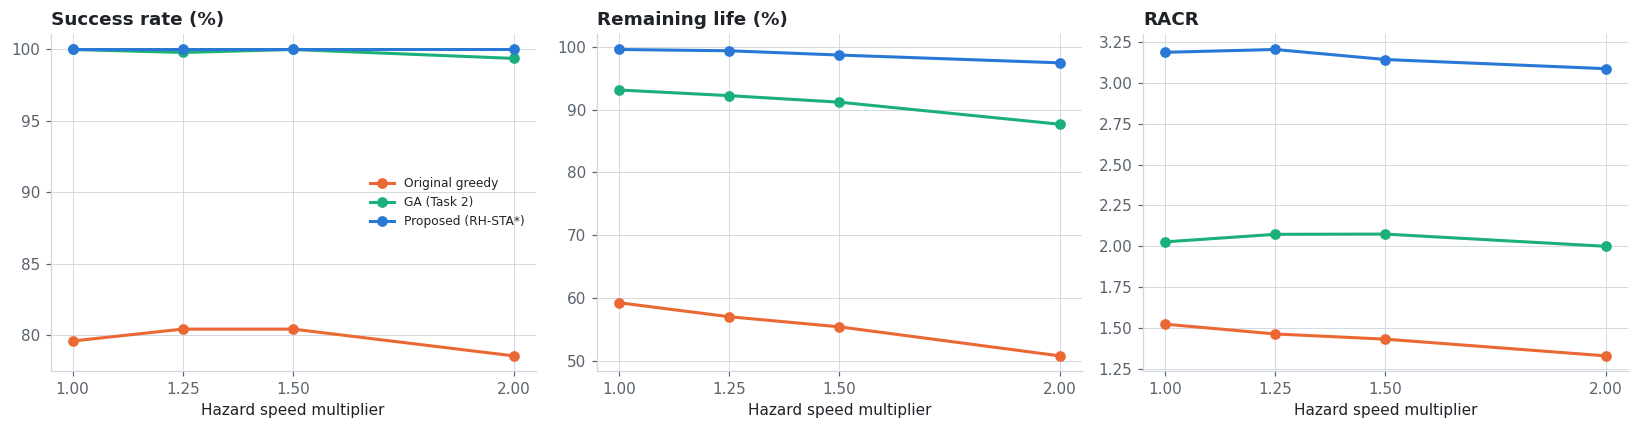

,agent,hazard_speed,success,time,life,racr
0,ga_task2,1.00,100.00,7.14,93.12,2.03
1,ga_task2,1.25,99.79,6.79,92.23,2.07
2,ga_task2,1.50,100.00,6.54,91.18,2.08
3,ga_task2,2.00,99.38,6.39,87.67,2.00
4,greedy,1.00,79.58,5.17,59.23,1.53
5,greedy,1.25,80.42,5.19,57.00,1.47
6,greedy,1.50,80.42,5.09,55.40,1.43
7,greedy,2.00,78.54,5.01,50.77,1.33
8,proposed,1.00,100.00,4.32,99.58,3.19
9,proposed,1.25,100.00,4.27,99.37,3.20


In [7]:
CSV_X = f'{OUT}/stress/per_run.csv'
runner.reset_if_changed(CSV_X, runner.proposed_code_tag())
runner.run_sweep(CSV_X, LEVELS, range(CFG['stress_seeds']), AGENTS, workers=WORKERS, hazard_speeds=CFG['stress_speeds'])
sx = pd.read_csv(CSV_X)
log_run('04_stress', episodes=len(sx))
st = sx.groupby(['agent', 'hazard_speed']).agg(success=('won', lambda s: 100 * s.mean()), time=('completion_time', 'mean'),
                                              life=('remaining_life', 'mean'), racr=('racr', 'mean')).reset_index()
st.to_csv(f'{OUT}/stress/stress_summary.csv', index=False); st.to_csv(f"{PATHS['report_tabs']}/table4_stress.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, ylab) in zip(axes, [('success', 'Success rate (%)'), ('life', 'Remaining life (%)'), ('racr', 'RACR')]):
    for a in AGENTS:
        s_ = st[st.agent == a]; ax.plot(s_.hazard_speed, s_[col], '-o', color=plots.color(a), lw=2, ms=6, label=plots.label(a))
    ax.set_xlabel('Hazard speed multiplier'); ax.set_title(ylab, loc='left'); ax.set_xticks(CFG['stress_speeds'])
axes[0].legend(fontsize=8); fig.tight_layout()
for d in (f'{OUT}/figures', PATHS['report_figs']): plots.save(fig, d, 'fig_stress_test.png')
plt.show(); display(st.round(2))

## 6. Same world, three agents (hardest levels)

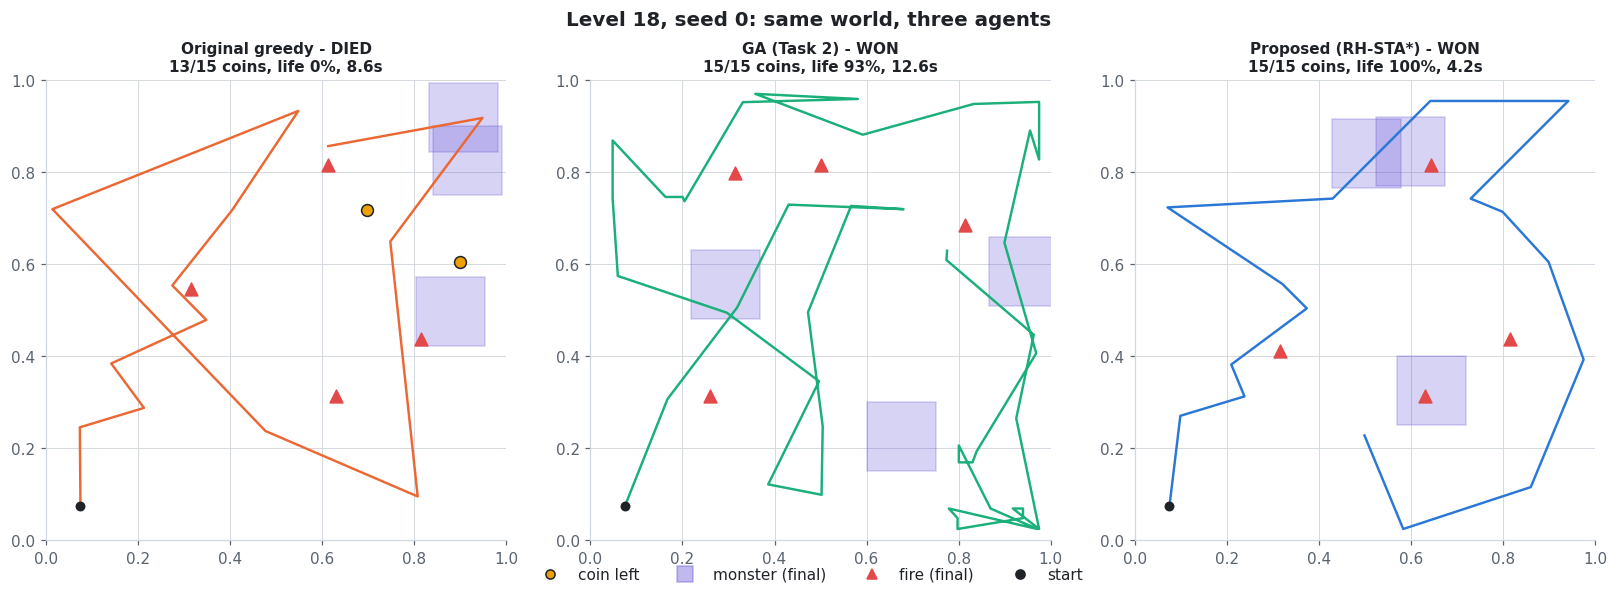

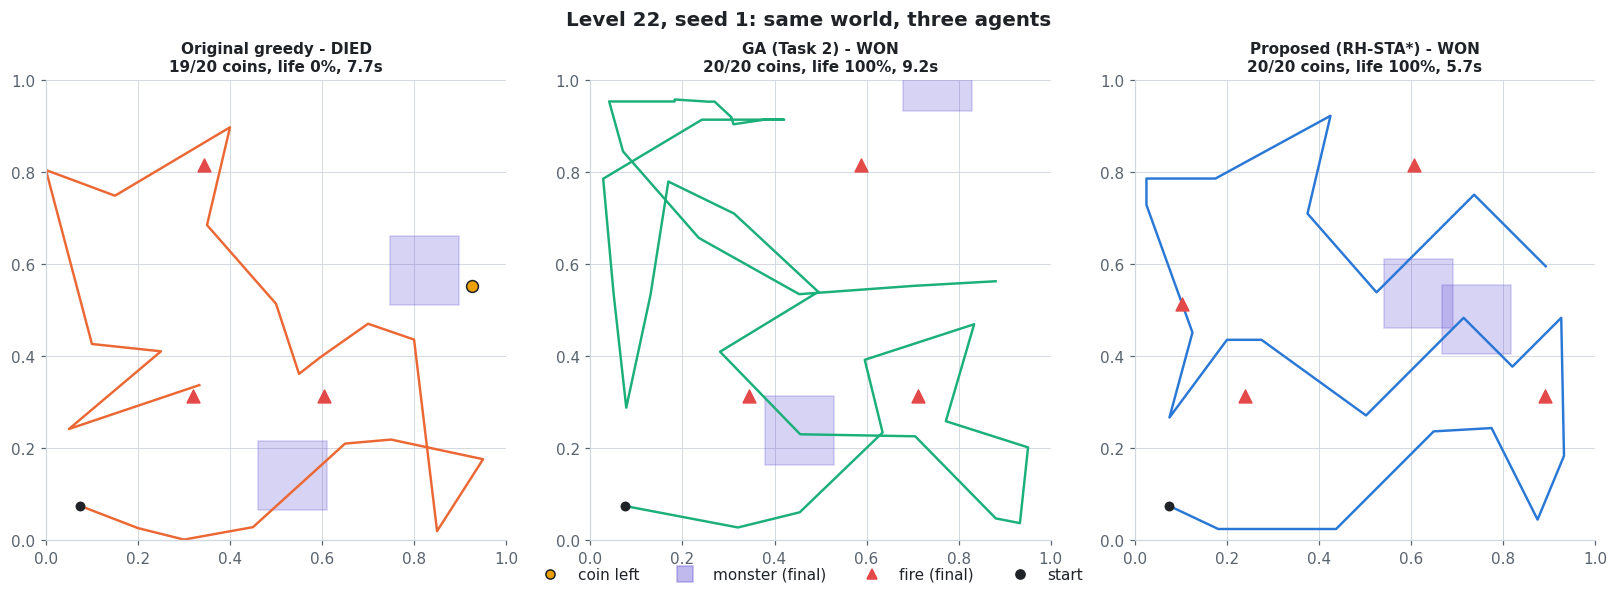

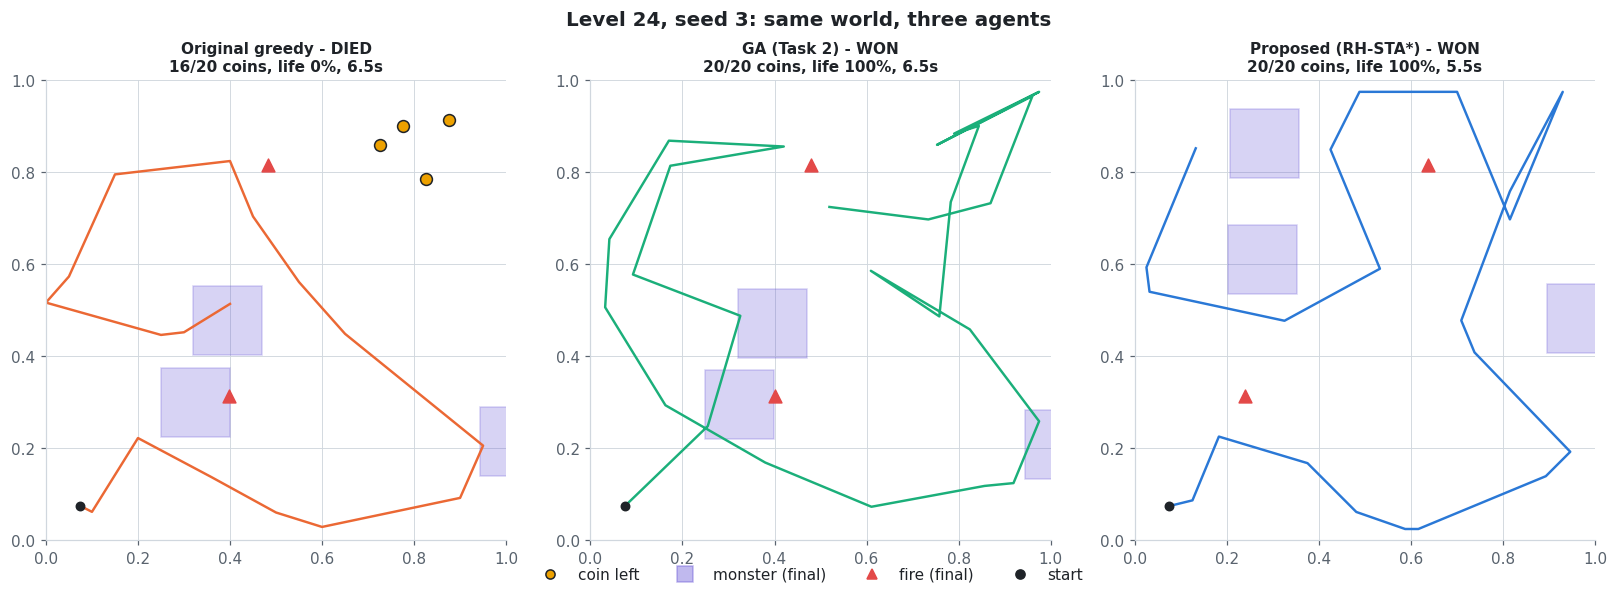

GIFs saved to /content/drive/MyDrive/COMP6009_Assignment-Part A/report_assets/figures


In [8]:
hard = runner.summarise(df[df.agent == 'greedy'], by=('agent', 'level')).sort_values('success_rate').level.head(3).tolist()
for lv in hard:
    pw = P['won'].reset_index()
    lost = pw[(pw.level == lv) & (pw.greedy == 0)]
    seed = int(lost.seed.min()) if len(lost) else 0          # a world where greedy fails
    traces = {a: runner.play_episode(lv, seed, a, record=True)[1] for a in AGENTS}
    fig = plots.trajectory_grid(traces, AGENTS, f'Level {lv}, seed {seed}: same world, three agents')
    for d in (f'{OUT}/figures', PATHS['report_figs']): plots.save(fig, d, f'fig_trajectories_L{lv}.png')
    plt.show()
    for a in AGENTS:
        plots.animate_episode(traces[a], a, f"{PATHS['report_figs']}/anim_L{lv}_s{seed}_{a}.gif")
print('GIFs saved to', PATHS['report_figs'])

## 7. Summary of all results
Saved to `deliverables/results_summary.md` and `.json`.

In [9]:
def fmt_tbl(d):
    return d.to_markdown() if hasattr(d, 'to_markdown') else d.to_string()
heads = {a: json.load(open(f"{p}/headline.json")) for a, p in
         [('greedy', PATHS['greedy']), ('proposed', PATHS['proposed']), ('ga_task2', PATHS['ga'])] if os.path.exists(f"{p}/headline.json")}
abl = pd.read_csv(f"{PATHS['proposed']}/tables/ablation_summary.csv") if os.path.exists(f"{PATHS['proposed']}/tables/ablation_summary.csv") else None
sens = pd.read_csv(f"{PATHS['proposed']}/tables/sensitivity_summary.csv") if os.path.exists(f"{PATHS['proposed']}/tables/sensitivity_summary.csv") else None
fail = pd.read_csv(f"{PATHS['greedy']}/tables/failure_causes_by_level.csv") if os.path.exists(f"{PATHS['greedy']}/tables/failure_causes_by_level.csv") else None
env = json.load(open(f"{PATHS['config']}/environment.json"))
lines = ['# CoinTex Part A - results summary', f"Generated {datetime.datetime.now():%Y-%m-%d %H:%M}  |  env: {env}",
         f"Config: {json.dumps(CFG)}", '', '## Table 1 - overall', fmt_tbl(table1.T), '',
         '## Table 2 - per level', fmt_tbl(wide), '', '## Table 3 - paired tests', fmt_tbl(tests), '',
         '## Completion-time 95% CI', fmt_tbl(ci), '', '## Stress test', fmt_tbl(st.round(2))]
if abl is not None: lines += ['', '## Ablation', fmt_tbl(abl.round(2))]
if sens is not None: lines += ['', '## Sensitivity (hard levels)', fmt_tbl(sens.round(2))]
if fail is not None: lines += ['', '## Greedy failure causes by level', fmt_tbl(fail)]
lines += ['', '## Headlines', '```json', json.dumps(heads, indent=1, default=str), '```']
text = '\n'.join(lines)
open(f"{PATHS['deliverables']}/results_summary.md", 'w').write(text)
json.dump({'table1': table1.reset_index().to_dict('records'), 'tests': tests.to_dict('records'),
           'stress': st.to_dict('records'), 'headlines': heads}, open(f"{PATHS['deliverables']}/results_summary.json", 'w'), indent=1, default=str)
print(text)

# CoinTex Part A - results summary
Generated 2026-10-21 19:01  |  env: {'python': '3.13.15', 'numpy': '2.1.3', 'pygad': '3.3.1', 'matplotlib': '3.10.0', 'cpus': 12, 'cointex_parta': '1.0.0'}
Config: {"levels": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24], "n_seeds": 50, "time_limit_s": 60.0, "stress_speeds": [1.0, 1.25, 1.5, 2.0], "stress_seeds": 20, "hard_levels": [7, 10, 11, 15, 16, 18, 21, 22, 23, 24], "sensitivity_seeds": 20}

## Table 1 - overall
|                        |   Original greedy |   GA (Task 2) |   Proposed (RH-STA*) |
|:-----------------------|------------------:|--------------:|---------------------:|
| episodes               |           1200    |       1200    |              1200    |
| success_rate           |             80.17 |        100    |               100    |
| levels_always_won      |              4    |         24    |                24    |
| levels_majority_won    |             20    |         24    |         